# Modeling Human Activity States with a Hidden Markov Model

**Author:** Amaliza Shalom · **Device:** iPhone 13 · **App:** Sensor Logger 1.68

I recorded standing, walking, jumping and still, then built a 4-state Gaussian HMM in NumPy (Baum-Welch to train, Viterbi to decode) and tested it on recordings it never saw.

**Run order:** `python scripts/prepare_data.py`, then this notebook top to bottom.

## 1. Setup and data loading

In [1]:
import itertools
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import logsumexp

# Works whether the notebook is run from the repo root or from notebook/
ROOT = Path.cwd() if (Path.cwd() / "Data_clean").exists() else Path.cwd().parent
DATA = ROOT / "Data_clean"
FIG = ROOT / "figures"
ART = ROOT / "artifacts"
FIG.mkdir(exist_ok=True)
ART.mkdir(exist_ok=True)

SEED = 42
STATES = ["standing", "walking", "jumping", "still"]
S2I = {s: i for i, s in enumerate(STATES)}
COLORS = {"standing": "#4C78A8", "walking": "#F58518", "jumping": "#E45756", "still": "#54A24B"}
SENSOR_COLS = ["ax", "ay", "az", "gx", "gy", "gz"]
pd.set_option("display.precision", 3)

manifest = pd.read_csv(DATA / "manifest.csv")
excluded = pd.read_csv(DATA / "excluded.csv")
trim_impact = pd.read_csv(DATA / "trim_rule_impact.csv")

def load_split(split: str) -> dict:
    """Load every cleaned recording of one split as {file name: (activity, DataFrame)}."""
    rows = manifest[manifest.split == split]
    return {r.new_name: (r.activity, pd.read_csv(DATA / split / r.new_name)) for r in rows.itertuples()}

train_files = load_split("train")
test_files = load_split("test")

summary = manifest.groupby(["activity", "split"]).agg(files=("new_name", "count"), seconds=("duration_s", "sum")).unstack()
summary[("files", "total")] = summary["files"].sum(axis=1)
summary[("seconds", "total")] = summary["seconds"].sum(axis=1)
summary[("seconds", "original")] = manifest.groupby("activity")["original_duration_s"].sum()
print(f"Train files: {len(train_files)} | Test files: {len(test_files)}")
display(summary.loc[STATES].round(1))
print("Excluded recordings:")
display(excluded)
print("Impact of a fixed 1.5 s trim at both ends with a 5 s minimum, compared with the rule I used:")
display(trim_impact)

Train files: 48 | Test files: 12


files       seconds        files seconds         
split     test train    test  train total   total original
activity                                                  
standing     3    12    15.3   64.8    15    80.2    106.2
walking      3    12    19.5   67.2    15    86.6    109.1
jumping      3    12    18.3   69.1    15    87.4    109.9
still        3    12    24.6  104.2    15   128.7    152.2

Excluded recordings:


,original_source,activity,recording_time,reason,evidence


Impact of a fixed 1.5 s trim at both ends with a 5 s minimum, compared with the rule I used:


,activity,recordings,original_s,fixed_rule_files_kept,fixed_rule_seconds_kept,adopted_rule_files_kept,adopted_rule_seconds_kept
0,jumping,15,109.9,1,6.1,15,87.4
1,standing,15,106.2,0,0.0,15,80.2
2,still,15,152.2,15,107.2,15,128.7
3,walking,15,109.1,3,15.4,15,86.6


**Cleaning** (`scripts/prepare_data.py`, raw files untouched):
- I use only the calibrated accelerometer and gyroscope. The uncalibrated accelerometer is in g and includes gravity.
- Sensors are merged by column name and nearest timestamp (5 ms tolerance).
- Standing, walking and jumping recordings are 6.3–9.1 s, so a 1.5 s trim at both ends with a 5 s minimum keeps only 4 of those 45. The disturbance is mostly at the start, so I trim 1.0 s from the start and 0.5 s from the end. Standing and still keep trimming while movement stays above 0.15 m/s².
- A recording stays if at least 4 s remains, which is three windows. Six kept files are under 5 s, so this relaxes the guideline. No file was dropped. Five still recordings ran past the 10 s limit, up to 12.5 s, and all are under 10 s after trimming.
- **Test set:** the last three recordings of each activity by start time. For standing, walking and jumping, training is 28 October and testing is 29 October. Still training and test are both from 31 October, minutes apart.
- **Still data:** this is my second batch, with the phone flat on a surface as the brief asks. The first was hand-held and scored 84.6 %. Section 10 covers what changed.

## 2. Sample data

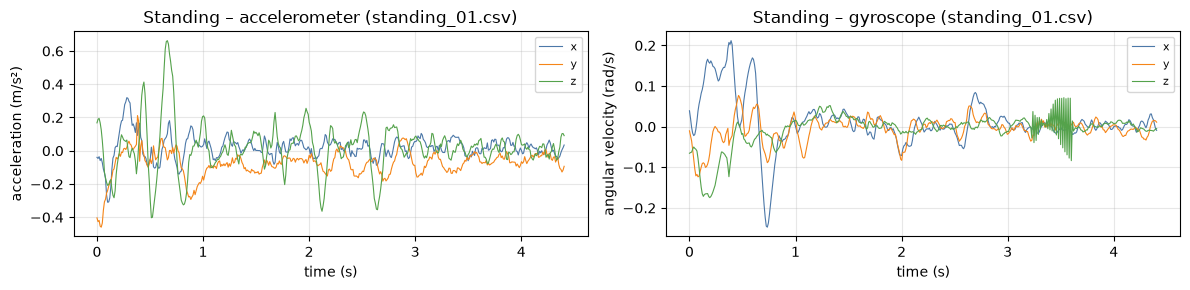

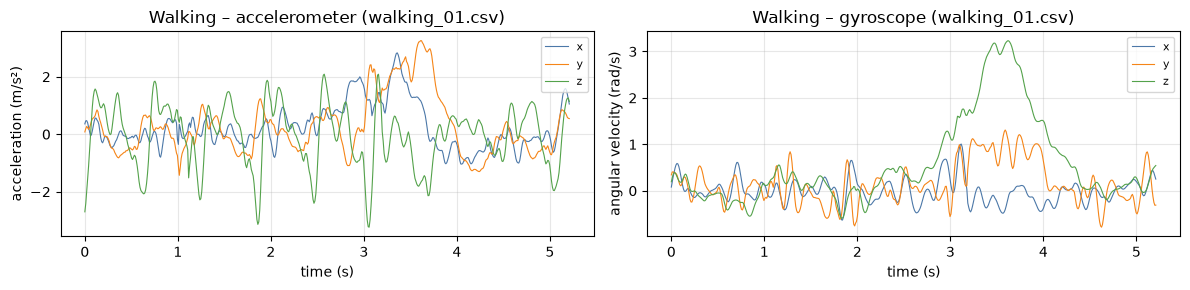

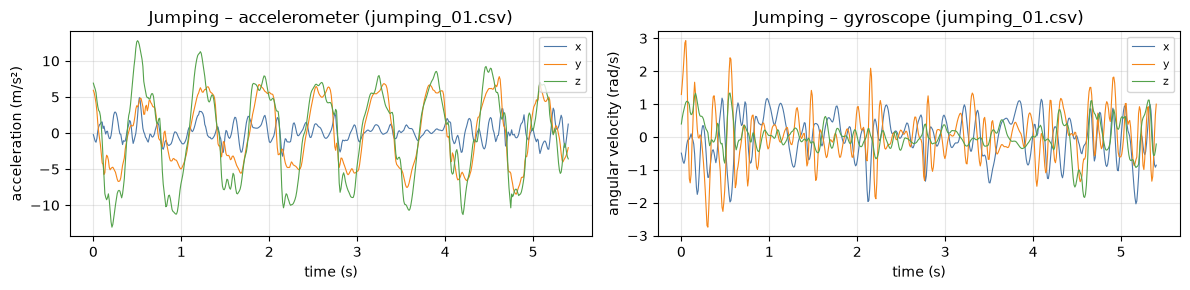

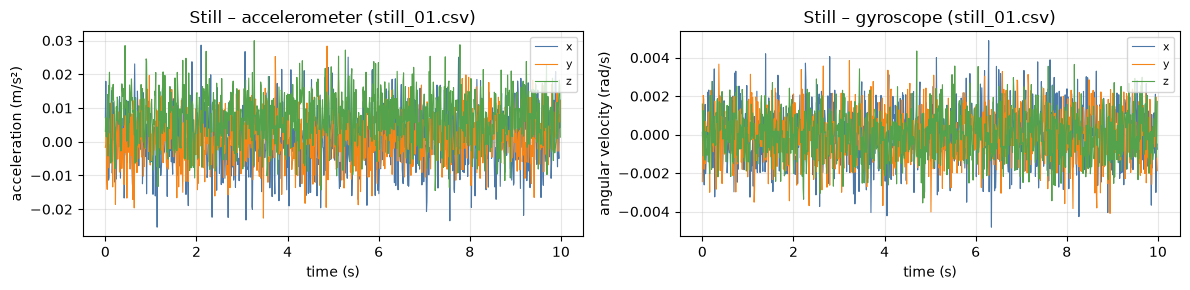

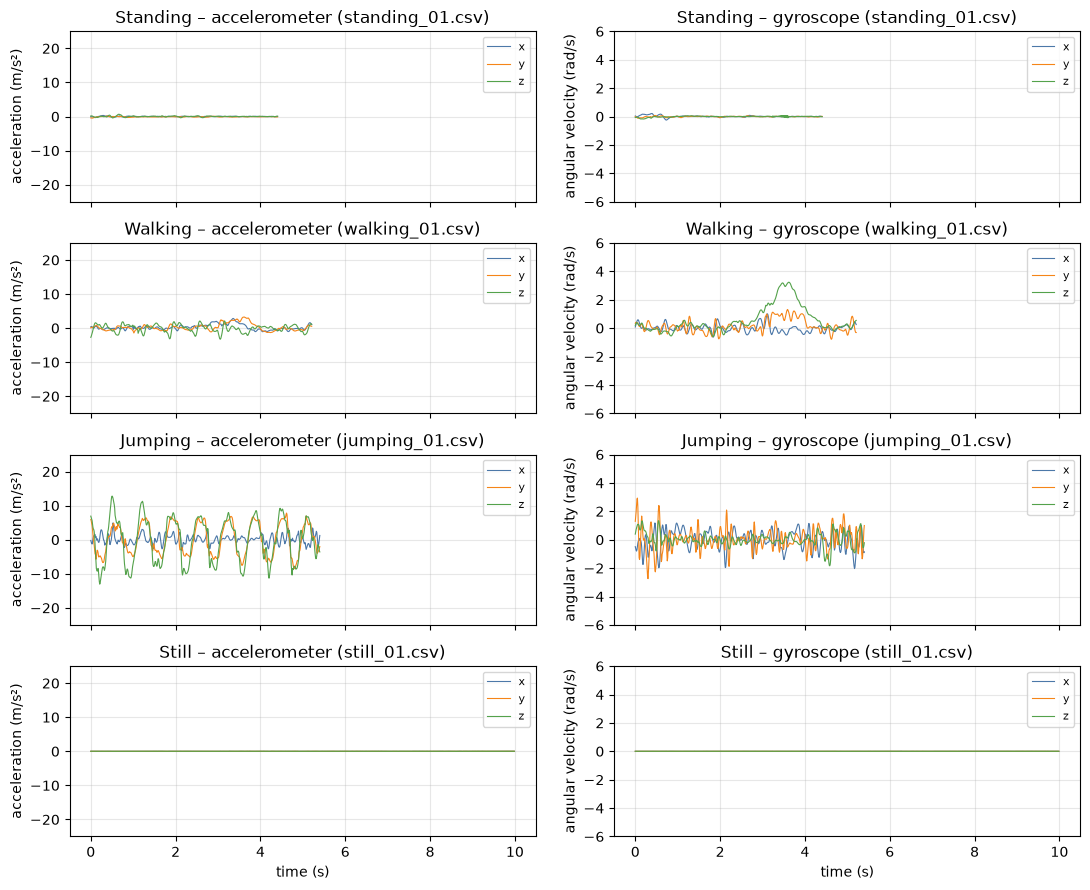

In [2]:
def plot_sample(activity, name, df, ax_acc, ax_gyr):
    """Plot one recording's accelerometer and gyroscope axes against time."""
    t = (df["timestamp"] - df["timestamp"].iloc[0]) / 1e9
    for c, col in zip(["x", "y", "z"], ["#4C78A8", "#F58518", "#54A24B"]):
        ax_acc.plot(t, df[f"a{c}"], color=col, lw=0.8, label=c)
        ax_gyr.plot(t, df[f"g{c}"], color=col, lw=0.8, label=c)
    ax_acc.set_title(f"{activity.capitalize()} – accelerometer ({name})")
    ax_gyr.set_title(f"{activity.capitalize()} – gyroscope ({name})")
    ax_acc.set_ylabel("acceleration (m/s²)")
    ax_gyr.set_ylabel("angular velocity (rad/s)")
    for a in (ax_acc, ax_gyr):
        a.set_xlabel("time (s)")
        a.grid(alpha=0.3)
        a.legend(loc="upper right", fontsize=8)

examples = {}
for act in STATES:
    name = next(n for n, (a, _) in train_files.items() if a == act)
    examples[act] = (name, train_files[name][1])
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3))
    plot_sample(act, name, examples[act][1], a1, a2)
    fig.tight_layout()
    fig.savefig(FIG / f"sample_{act}.png", dpi=150, bbox_inches="tight")
    plt.show()

# Combined figure for the report, with a shared y-range per sensor so amplitudes are comparable
fig, axes = plt.subplots(4, 2, figsize=(11, 9), sharex=True)
for i, act in enumerate(STATES):
    plot_sample(act, *examples[act], axes[i, 0], axes[i, 1])
for j, lim in enumerate([25, 6]):
    for i in range(4):
        axes[i, j].set_ylim(-lim, lim)
        if i < 3:
            axes[i, j].set_xlabel("")
fig.tight_layout()
fig.savefig(FIG / "sample_signals.png", dpi=150, bbox_inches="tight")
plt.show()

Jumping swings about ±10 m/s² and walking has a smaller step pattern. At this scale standing and still both look flat, so that pair is the one to watch. Section 10 zooms in.

## 3. Sampling rate (verified, not assumed)

In [3]:
def interval_stats(df: pd.DataFrame) -> dict:
    """Sampling-rate statistics computed from the timestamps of one recording."""
    dt = np.diff(df["timestamp"].to_numpy(np.int64)) / 1e9
    return {"measured_hz": 1 / np.median(dt), "dt_min_ms": dt.min() * 1e3, "dt_max_ms": dt.max() * 1e3,
            "dt_std_ms": dt.std() * 1e3, "rows": len(df), "duration_s": (len(df) - 1) * np.median(dt)}

qc = pd.DataFrame([{"file": n, "activity": a, "split": s, **interval_stats(df)}
                   for s, files in (("train", train_files), ("test", test_files)) for n, (a, df) in files.items()])
qc = qc.merge(manifest[["new_name", "original_duration_s", "n_unmatched", "acc_mag_std", "gyr_mag_std"]],
              left_on="file", right_on="new_name").drop(columns="new_name")
print("Per-file quality control (first 8 of", len(qc), "files; full table in Data_clean/manifest.csv):")
display(qc.head(8).round(3))
print(qc["measured_hz"].describe()[["count", "mean", "std", "min", "max"]].round(4).to_string())
print(f"Sample interval over all files: {qc.dt_min_ms.min():.3f}–{qc.dt_max_ms.max():.3f} ms")
display(qc.groupby("activity")[["measured_hz", "acc_mag_std", "gyr_mag_std"]].median().loc[STATES].round(4))

FS = qc["measured_hz"].mean()
assert qc["measured_hz"].std() < 0.05 and qc["dt_max_ms"].max() < 15, "Sampling rate is not uniform"
print(f"Sampling rate used for windowing: FS = {FS:.2f} Hz")

Per-file quality control (first 8 of 60 files; full table in Data_clean/manifest.csv):


,file,activity,split,measured_hz,dt_min_ms,dt_max_ms,dt_std_ms,rows,duration_s,original_duration_s,n_unmatched,acc_mag_std,gyr_mag_std
0,jumping_01.csv,jumping,train,99.453,10.054,10.056,0.0,538,5.400,6.898,0,3.094,0.562
1,jumping_02.csv,jumping,train,99.453,10.054,10.056,0.0,602,6.043,7.541,0,3.376,0.532
2,jumping_03.csv,jumping,train,99.452,10.055,10.056,0.0,538,5.400,6.898,0,4.166,0.615
3,jumping_04.csv,jumping,train,99.453,10.054,10.056,0.0,496,4.977,6.476,0,4.491,0.596
4,jumping_05.csv,jumping,train,99.453,10.055,10.056,0.0,567,5.691,7.189,0,5.244,0.533
5,jumping_06.csv,jumping,train,99.453,10.054,10.056,0.0,577,5.792,7.290,0,6.499,0.584
6,jumping_07.csv,jumping,train,99.453,10.054,10.055,0.0,557,5.591,7.089,0,5.812,0.563
7,jumping_08.csv,jumping,train,99.454,10.053,10.056,0.0,554,5.560,7.058,0,7.118,0.747


count    60.000
mean     99.447
std       0.006
min      99.432
max      99.454
Sample interval over all files: 10.053–10.058 ms


,measured_hz,acc_mag_std,gyr_mag_std
activity,,,
standing,99.453,0.035,0.021
walking,99.443,0.597,0.669
jumping,99.453,4.491,0.573
still,99.443,0.008,0.001


Sampling rate used for windowing: FS = 99.45 Hz


I measured the rate from the timestamps instead of trusting the 10 ms setting. It is about 99.45 Hz in every file, with no missing or out-of-order samples, so **no resampling was needed**. The assert above stops the notebook if that changes. Movement variability goes jumping ≫ walking ≫ standing > still.

## 4. Windowing

In [4]:
WIN_S, OVERLAP = 2.0, 0.5
WIN = int(round(WIN_S * FS))          # samples per window
STEP = int(WIN * (1 - OVERLAP))       # hop size

def make_windows(x: np.ndarray) -> list:
    """Split a (n_samples, 6) array into WIN-sample windows with hop STEP.

    Only complete windows are returned: no padding, and the incomplete tail is dropped.
    A recording shorter than WIN gives no windows.
    """
    return [x[s:s + WIN] for s in range(0, len(x) - WIN + 1, STEP)]

print(f"Window = {WIN} samples ({WIN / FS:.2f} s), step = {STEP} samples ({STEP / FS:.2f} s), "
      f"FFT bin spacing = {FS / WIN:.2f} Hz")

Window = 199 samples (2.00 s), step = 99 samples (1.00 s), FFT bin spacing = 0.50 Hz


**2 s windows with 50 % overlap** (199 samples, 99-sample hop):
- 2 s covers 2–3 of my steps.
- The FFT grid is about 0.5 Hz, enough to separate walking and jumping rhythms from static noise.
- A cleaned recording of 4.4–10.0 s gives 3–9 windows.

All windows of a recording stay in that recording's split.

## 5. Feature extraction

In [5]:
AXIS_PAIRS = [(0, 1), (0, 2), (1, 2)]

def spectral_features(sig: np.ndarray) -> tuple:
    """Dominant frequency (Hz), spectral energy and spectral entropy (bits) of one axis.

    The mean is removed first, so the DC bin is ~0 and is excluded. Spectral energy is the mean power
    2/N² · Σ_k |X_k|² over the positive-frequency bins. By Parseval this is approximately the window
    variance, in (unit)², e.g. (m/s²)² for the accelerometer. A flat signal gets a uniform spectrum
    (maximum entropy) instead of a division by zero.
    """
    sig = sig - sig.mean()
    n = len(sig)
    power = np.abs(np.fft.rfft(sig)) ** 2
    freqs = np.fft.rfftfreq(n, 1 / FS)
    power, freqs = power[1:], freqs[1:]
    total = power.sum()
    p = power / total if total > 0 else np.full_like(power, 1 / len(power))
    return freqs[power.argmax()], 2 * total / n ** 2, -(p * np.log2(p + 1e-12)).sum()

def extract_features(w: np.ndarray) -> tuple:
    """22 features per sensor (accelerometer, gyroscope) -> 44 features for one (WIN, 6) window."""
    feats, names = [], []
    for s, sensor in ((0, "acc"), (3, "gyr")):
        xyz = w[:, s:s + 3]
        for i, ax in enumerate("xyz"):
            feats += [xyz[:, i].mean(), xyz[:, i].std(), np.sqrt((xyz[:, i] ** 2).mean())]
            names += [f"{sensor}_{ax}_mean", f"{sensor}_{ax}_std", f"{sensor}_{ax}_rms"]
        feats.append(np.abs(xyz).sum(axis=1).mean())
        names.append(f"{sensor}_sma")
        for i, j in AXIS_PAIRS:
            c = np.corrcoef(xyz[:, i], xyz[:, j])[0, 1] if xyz[:, i].std() > 0 and xyz[:, j].std() > 0 else 0.0
            feats.append(c)
            names.append(f"{sensor}_corr_{'xyz'[i]}{'xyz'[j]}")
        for i, ax in enumerate("xyz"):
            feats += list(spectral_features(xyz[:, i]))
            names += [f"{sensor}_{ax}_domfreq", f"{sensor}_{ax}_energy", f"{sensor}_{ax}_entropy"]
    return np.array(feats), names

def file_features(files: dict, split: str) -> tuple:
    """Feature matrix per recording, plus a table linking every window to its file and time interval."""
    out, index = {}, []
    for name, (act, df) in files.items():
        wins = make_windows(df[SENSOR_COLS].to_numpy())
        if not wins:
            print(f"Skipped {name}: shorter than one window")
            continue
        out[name] = (act, np.array([extract_features(w)[0] for w in wins]))
        index += [(name, act, split, k, k * STEP / FS, (k * STEP + WIN) / FS) for k in range(len(wins))]
    return out, pd.DataFrame(index, columns=["file", "activity", "split", "window", "start_s", "end_s"])

FEATURE_NAMES = extract_features(np.zeros((WIN, 6)))[1]
train_feats, train_index = file_features(train_files, "train")
test_feats, test_index = file_features(test_files, "test")
window_index = pd.concat([train_index, test_index], ignore_index=True)
window_index.to_csv(ART / "window_index.csv", index=False)
print(f"{len(FEATURE_NAMES)} features | train windows: {len(train_index)} | test windows: {len(test_index)}")
display(window_index.groupby(["activity", "split"]).size().unstack().loc[STATES])

tr_all = pd.DataFrame(np.vstack([F for _, F in train_feats.values()]), columns=FEATURE_NAMES)
tr_all["activity"] = train_index["activity"].to_numpy()
key = ["acc_sma", "acc_x_std", "gyr_sma", "acc_y_domfreq", "acc_z_domfreq", "acc_z_energy", "gyr_z_entropy"]
display(tr_all.groupby("activity")[key].median().loc[STATES])

44 features | train windows: 236 | test windows: 61


split,test,train
activity,,
standing,11,47
walking,15,50
jumping,14,51
still,21,88


,acc_sma,acc_x_std,gyr_sma,acc_y_domfreq,acc_z_domfreq,acc_z_energy,gyr_z_entropy
activity,,,,,,,
standing,0.109,0.045,0.034,2.499,4.997,2.765e-03,2.744
walking,1.863,0.594,1.209,0.999,1.499,7.235e-01,1.999
jumping,12.128,1.148,1.496,1.499,1.499,8.422e+01,3.438
still,0.021,0.008,0.003,18.740,15.492,5.823e-05,6.035


Each window gets 44 features, 22 per sensor.

| Group | Features | Why |
|---|---|---|
| Time | mean, std, RMS per axis | How much the phone moves |
| Time | SMA | One intensity number across axes |
| Time | xy, xz, yz correlation | Body movement links the axes, noise does not |
| Frequency | dominant frequency per axis | Rhythm of steps or jumps |
| Frequency | spectral energy per axis | Power of the movement |
| Frequency | spectral entropy per axis | Periodic signals score low, noise scores high |

`acc_sma` rises from still to standing to walking to jumping, as expected. Still's dominant frequency is about 15–19 Hz, which is sensor noise, not motion. Its gyroscope entropy is high for the same reason: noise spreads evenly across frequencies, while slow hand sway in standing does not.

In [6]:
# Feature quality checks
F_tr = tr_all[FEATURE_NAMES].to_numpy()
F_te = np.vstack([F for _, F in test_feats.values()])
assert np.isfinite(F_tr).all() and np.isfinite(F_te).all(), "Non-finite feature values"
const = [n for n, s in zip(FEATURE_NAMES, F_tr.std(0)) if s < 1e-10]
corr = np.corrcoef(F_tr.T)
redundant = [(FEATURE_NAMES[i], FEATURE_NAMES[j], round(corr[i, j], 3))
             for i in range(len(FEATURE_NAMES)) for j in range(i + 1, len(FEATURE_NAMES)) if abs(corr[i, j]) > 0.98]
print("All feature values finite ✓")
print("Constant features:", const or "none")
print(f"Highly redundant pairs (|r| > 0.98 on training windows): {len(redundant)}")
for r in redundant:
    print("  ", r)

All feature values finite ✓
Constant features: none
Highly redundant pairs (|r| > 0.98 on training windows): 6
   ('acc_x_std', 'acc_x_rms', np.float64(0.996))
   ('acc_y_std', 'acc_y_rms', np.float64(0.999))
   ('acc_z_std', 'acc_z_rms', np.float64(1.0))
   ('acc_z_std', 'acc_sma', np.float64(0.989))
   ('acc_z_rms', 'acc_sma', np.float64(0.989))
   ('gyr_x_std', 'gyr_x_rms', np.float64(1.0))


The duplicates are mostly std and RMS: the mean is about 0 without gravity, so they match. I keep both because the rubric asks for both, but the diagonal model counts that information twice.

## 6. Normalization (z-score, fit on training data only)

In [7]:
def fit_zscore(F_train: np.ndarray) -> tuple:
    """Mean and std of each feature over the training windows; near-constant features get scale 1."""
    mu = F_train.mean(0)
    sd = F_train.std(0, ddof=1)
    return mu, np.where(sd < 1e-8, 1.0, sd)

MU, SD = fit_zscore(F_tr)

def zscore(F: np.ndarray) -> np.ndarray:
    """Normalise features with the training-set mean and std."""
    return (F - MU) / SD

train_z = {n: (a, zscore(F)) for n, (a, F) in train_feats.items()}
test_z = {n: (a, zscore(F)) for n, (a, F) in test_feats.items()}
pd.DataFrame({"feature": FEATURE_NAMES, "mean": MU, "std": SD}).to_csv(ART / "zscore_params.csv", index=False)
Ztr = np.vstack([F for _, F in train_z.values()])
print(f"Train features after scaling: max |mean| = {np.abs(Ztr.mean(0)).max():.2e}, std range {Ztr.std(0, ddof=1).min():.3f}–{Ztr.std(0, ddof=1).max():.3f}")
print("Parameters saved to artifacts/zscore_params.csv")

Train features after scaling: max |mean| = 4.10e-16, std range 1.000–1.000
Parameters saved to artifacts/zscore_params.csv


The features have very different scales, and Gaussian emissions are sensitive to scale. I fit the z-score on **training windows only** and apply it to test windows. Section 8 tests this.

## 7. Hidden Markov Model (implemented from scratch)

- **States Z:** standing, walking, jumping, still.
- **Observations X:** the 44 z-scored features of a window.
- **Emissions B:** one Gaussian per state, diagonal covariance, variance floor 0.01. Diagonal is an approximation, but 236 training windows can't support a full 44 × 44 covariance.
- **A:** transitions between consecutive windows of one recording.
- **π:** the state of a recording's first window.

**Sequences.** Each recording is its own sequence, and each holds one activity. So A only shows how long an activity lasts, not how people switch.

**Start values.** Means, variances, A and π come from the labelled training windows, with add-one smoothing.

**Algorithms.** Viterbi finds the most likely activity path. Baum-Welch refines A, B and π without labels. A higher likelihood doesn't guarantee higher accuracy, so I report both.

In [8]:
class GaussianHMM:
    """Hidden Markov Model with diagonal-covariance Gaussian emissions, written in NumPy."""

    def __init__(self, n_states: int, var_floor: float = 1e-2, prob_floor: float = 1e-6):
        self.K = n_states
        self.var_floor = var_floor
        self.prob_floor = prob_floor

    def init_supervised(self, X_list: list, y_list: list):
        """Initialise from labelled sequences.

        Means/variances come from the pooled labelled windows. A comes from within-sequence transition
        counts and pi from the first label of each sequence, both with add-one smoothing.
        """
        X, y = np.vstack(X_list), np.concatenate(y_list)
        self.means = np.array([X[y == k].mean(0) for k in range(self.K)])
        self.vars = np.maximum(np.array([X[y == k].var(0) for k in range(self.K)]), self.var_floor)
        counts = np.ones((self.K, self.K))
        first = np.ones(self.K)
        for ys in y_list:
            first[ys[0]] += 1
            for a, b in zip(ys[:-1], ys[1:]):
                counts[a, b] += 1
        self.A = counts / counts.sum(1, keepdims=True)
        self.pi = first / first.sum()
        return self

    def log_emission(self, X: np.ndarray) -> np.ndarray:
        """log p(x_t | z_t = k) for every t and k, shape (T, K)."""
        diff = X[:, None, :] - self.means[None]
        return -0.5 * (np.log(2 * np.pi * self.vars)[None] + diff ** 2 / self.vars[None]).sum(-1)

    @staticmethod
    def _log(p: np.ndarray) -> np.ndarray:
        """log that maps exact zeros (impossible transitions) to -inf without a warning."""
        with np.errstate(divide="ignore"):
            return np.log(p)

    def forward_backward(self, X: np.ndarray) -> tuple:
        """Log-space forward-backward. Returns log_alpha, log_beta, logB and the sequence log-likelihood."""
        logB, logA = self.log_emission(X), self._log(self.A)
        T = len(X)
        la = np.empty((T, self.K))
        lb = np.zeros((T, self.K))
        la[0] = self._log(self.pi) + logB[0]
        for t in range(1, T):
            la[t] = logsumexp(la[t - 1][:, None] + logA, axis=0) + logB[t]
        for t in range(T - 2, -1, -1):
            lb[t] = logsumexp(logA + (logB[t + 1] + lb[t + 1])[None], axis=1)
        return la, lb, logB, logsumexp(la[-1])

    def score(self, X_list: list) -> float:
        """Total log-likelihood of a list of independent sequences."""
        return sum(self.forward_backward(X)[3] for X in X_list)

    def fit(self, X_list: list, eps: float = 1e-4, min_iter: int = 3, max_iter: int = 500) -> list:
        """Baum-Welch (EM) over independent sequences.

        Stops when |delta log-likelihood| < eps after at least min_iter iterations; max_iter is only a
        safeguard, and stopping there is reported as *not converged*. Probabilities are floored at
        prob_floor and variances at var_floor. Returns the log-likelihood history.
        """
        self.history, self.converged, self.converged_iter = [], False, None
        for it in range(max_iter):
            ll_total = 0.0
            g_first, g_from, g_sum = np.zeros(self.K), np.zeros(self.K), np.zeros(self.K)
            xi_sum = np.zeros((self.K, self.K))
            mx, mxx = np.zeros_like(self.means), np.zeros_like(self.means)
            logA = self._log(self.A)
            for X in X_list:                                             # accumulate statistics per sequence
                la, lb, logB, ll = self.forward_backward(X)
                ll_total += ll
                gamma = np.exp(la + lb - ll)                             # P(z_t = k | X), shape (T, K)
                if len(X) > 1:
                    log_xi = la[:-1, :, None] + logA[None] + (logB[1:] + lb[1:])[:, None, :] - ll
                    xi_sum += np.exp(log_xi).sum(0)                      # expected transitions i -> j
                    g_from += gamma[:-1].sum(0)
                g_first += gamma[0]
                g_sum += gamma.sum(0)
                mx += gamma.T @ X
                mxx += gamma.T @ (X ** 2)
            if not np.isfinite(ll_total):
                raise FloatingPointError(f"Non-finite log-likelihood at iteration {it}")
            self.history.append(ll_total)
            # M-step
            self.pi = np.maximum(g_first / g_first.sum(), self.prob_floor)
            self.pi /= self.pi.sum()
            A = xi_sum / np.maximum(g_from, 1e-300)[:, None]
            self.A = np.maximum(A, self.prob_floor)
            self.A /= self.A.sum(1, keepdims=True)
            denom = np.maximum(g_sum, 1e-10)[:, None]
            self.means = mx / denom
            self.vars = np.maximum(mxx / denom - self.means ** 2, self.var_floor)
            if it + 1 >= min_iter and abs(self.history[-1] - self.history[-2]) < eps:
                self.converged, self.converged_iter = True, it
                break
        self.history.append(self.score(X_list))                         # likelihood of the final parameters
        self.ll_decreases = int((np.diff(self.history) < -1e-6 * abs(self.history[0])).sum())
        return self.history

    def viterbi(self, X: np.ndarray) -> tuple:
        """Most likely state sequence (log space). Returns (path, log-probability of the path)."""
        logB, logA = self.log_emission(X), self._log(self.A)
        T = len(X)
        delta = np.empty((T, self.K))
        psi = np.zeros((T, self.K), dtype=int)
        delta[0] = self._log(self.pi) + logB[0]
        for t in range(1, T):
            cand = delta[t - 1][:, None] + logA
            psi[t] = cand.argmax(0)
            delta[t] = cand.max(0) + logB[t]
        path = np.empty(T, dtype=int)
        path[-1] = delta[-1].argmax()
        for t in range(T - 2, -1, -1):
            path[t] = psi[t + 1, path[t + 1]]
        return path, delta[-1].max()

Training sequences: 48 recordings, 236 windows
Converged: True at iteration 2 (|ΔLL| < 1e-4, max 500)
Log-likelihood: initial 1261.753 -> final 1273.096
Log-likelihood decreases during EM: 0


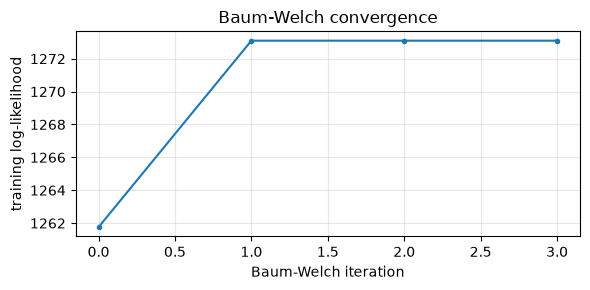

In [9]:
# Training: one independent sequence per training recording (windows in time order)
train_names = list(train_z)
X_train = [train_z[n][1] for n in train_names]
y_train = [np.full(len(train_z[n][1]), S2I[train_z[n][0]]) for n in train_names]

hmm_init = GaussianHMM(len(STATES)).init_supervised(X_train, y_train)
hmm = GaussianHMM(len(STATES)).init_supervised(X_train, y_train)
history = hmm.fit(X_train, eps=1e-4, min_iter=3, max_iter=500)

print(f"Training sequences: {len(X_train)} recordings, {sum(len(x) for x in X_train)} windows")
print(f"Converged: {hmm.converged} at iteration {hmm.converged_iter} (|ΔLL| < 1e-4, max 500)")
print(f"Log-likelihood: initial {history[0]:.3f} -> final {history[-1]:.3f}")
print(f"Log-likelihood decreases during EM: {hmm.ll_decreases}")

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(range(len(history)), history, marker="o", ms=3)
ax.set_xlabel("Baum-Welch iteration")
ax.set_ylabel("training log-likelihood")
ax.set_title("Baum-Welch convergence")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "baum_welch_convergence.png", dpi=150, bbox_inches="tight")
plt.show()

Baum-Welch ignores labels, so I map each state to the activity it decodes most on **training data only**, and check the mapping is one-to-one.

In [10]:
def state_mapping(model: GaussianHMM, X_list: list, y_list: list) -> tuple:
    """Map each HMM state to the training activity it is decoded on most often (training data only)."""
    cm = np.zeros((model.K, model.K), dtype=int)                       # rows: state, cols: true label
    for X, y in zip(X_list, y_list):
        for s, l in zip(model.viterbi(X)[0], y):
            cm[s, l] += 1
    mapping = cm.argmax(1)
    return mapping, cm

mapping, map_cm = state_mapping(hmm, X_train, y_train)
assert sorted(mapping) == list(range(len(STATES))), "State mapping is not one-to-one"
print("State -> activity mapping:", {f"state {k}": STATES[m] for k, m in enumerate(mapping)})
display(pd.DataFrame(map_cm, index=[f"state {k}" for k in range(len(STATES))], columns=STATES))

def train_accuracy(model, mapping):
    """Window accuracy of Viterbi on the training recordings, each decoded on its own."""
    pred = np.concatenate([mapping[model.viterbi(X)[0]] for X in X_train])
    return (pred == np.concatenate(y_train)).mean()

init_mapping = state_mapping(hmm_init, X_train, y_train)[0]
print(f"Training accuracy: initial model {train_accuracy(hmm_init, init_mapping):.3f} | after Baum-Welch {train_accuracy(hmm, mapping):.3f}")
np.savez(ART / "hmm_params.npz", A=hmm.A, pi=hmm.pi, means=hmm.means, vars=hmm.vars, mapping=mapping, states=STATES)

State -> activity mapping: {'state 0': 'standing', 'state 1': 'walking', 'state 2': 'jumping', 'state 3': 'still'}


,standing,walking,jumping,still
state 0,47,0,0,0
state 1,0,50,0,0
state 2,0,0,51,0
state 3,0,0,0,88


Training accuracy: initial model 1.000 | after Baum-Welch 1.000


## 8. Automated tests

These run every time. They check the algorithms against brute force on a 2-state toy model (all 32 paths), then the trained model, features, normalization and split.

In [11]:
def toy_model() -> GaussianHMM:
    m = GaussianHMM(2, var_floor=1e-6)
    m.means, m.vars = np.array([[0.0], [3.0]]), np.array([[1.0], [1.0]])
    m.A, m.pi = np.array([[0.9, 0.1], [0.2, 0.8]]), np.array([0.6, 0.4])
    return m

def brute_force(m: GaussianHMM, X: np.ndarray) -> tuple:
    """Exact log p(X) and best path by enumerating every state path."""
    logB, logA, lpi = m.log_emission(X), np.log(m.A), np.log(m.pi)
    scores = {p: lpi[p[0]] + logB[0, p[0]] + sum(logA[p[t - 1], p[t]] + logB[t, p[t]] for t in range(1, len(X)))
              for p in itertools.product(range(m.K), repeat=len(X))}
    best = max(scores, key=scores.get)
    return logsumexp(list(scores.values())), np.array(best), scores[best]

results = []
def check(name, cond):
    results.append((name, bool(cond)))
    assert cond, name

m, Xs = toy_model(), np.array([[0.1], [2.9], [3.2], [0.2], [1.5]])
ll_bf, path_bf, lp_bf = brute_force(m, Xs)
path, lp = m.viterbi(Xs)
check("forward log-likelihood equals brute-force sum over all paths", np.isclose(m.forward_backward(Xs)[3], ll_bf))
check("Viterbi path equals brute-force best path", np.array_equal(path, path_bf) and np.isclose(lp, lp_bf))
check("Viterbi is deterministic", all(np.array_equal(m.viterbi(Xs)[0], path) for _ in range(3)))
m0 = toy_model(); m0.A = np.array([[1.0, 0.0], [0.5, 0.5]])
p0, lp0 = m0.viterbi(Xs)
check("Viterbi never uses an impossible (zero-probability) transition", np.isfinite(lp0) and not any((a, b) == (0, 1) for a, b in zip(p0[:-1], p0[1:])))

# Baum-Welch on data sampled from the toy model, starting from wrong parameters
rng = np.random.default_rng(SEED)
def sample(m, T):
    z = [rng.choice(2, p=m.pi)]
    for _ in range(T - 1):
        z.append(rng.choice(2, p=m.A[z[-1]]))
    z = np.array(z)
    return rng.normal(m.means[z, 0], np.sqrt(m.vars[z, 0]))[:, None]
seqs = [sample(toy_model(), 80) for _ in range(6)]
bw = GaussianHMM(2, var_floor=1e-3)
bw.means, bw.vars = np.array([[-1.0], [1.0]]), np.array([[2.0], [2.0]])
bw.A, bw.pi = np.full((2, 2), 0.5), np.array([0.5, 0.5])
h = bw.fit(seqs, eps=1e-6, max_iter=500)
check("Baum-Welch log-likelihood never decreases (toy data)", bw.ll_decreases == 0)
check("Baum-Welch converges on toy data", bw.converged)
check("Baum-Welch recovers the toy means (±0.3)", np.allclose(np.sort(bw.means[:, 0]), [0.0, 3.0], atol=0.3))

# The trained model
check("A rows sum to 1", np.allclose(hmm.A.sum(1), 1))
check("pi sums to 1", np.isclose(hmm.pi.sum(), 1))
check("all emission variances positive", (hmm.vars > 0).all())
check("finite log-likelihood for every training sequence", all(np.isfinite(hmm.forward_backward(X)[3]) for X in X_train))
check("trained model converged (not stopped by max_iter)", hmm.converged)
check("no log-likelihood decrease during training", hmm.ll_decreases == 0)
tp = hmm.viterbi(X_train[0])[0]
check("Viterbi output has one valid state per window", len(tp) == len(X_train[0]) and set(tp) <= set(range(len(STATES))))

# Windows and features
check("window count and length are correct", len(make_windows(np.zeros((500, 6)))) == (500 - WIN) // STEP + 1
      and all(len(w) == WIN for w in make_windows(np.zeros((500, 6)))))
check("a recording shorter than one window gives no windows", make_windows(np.zeros((WIN - 1, 6))) == [])
tt = np.arange(WIN) / FS
f_dom, energy, _ = spectral_features(np.sin(2 * np.pi * 2.0 * tt))
check("FFT dominant frequency of a 2 Hz sine is within one bin", abs(f_dom - 2.0) <= FS / WIN)
check("spectral energy ≈ variance (Parseval)", np.isclose(energy, np.sin(2 * np.pi * 2.0 * tt).var(), rtol=0.02))
check("flat signal gives finite spectral features", np.isfinite(spectral_features(np.ones(WIN))).all())

# Normalization and split
check("z-score parameters equal the training statistics", np.allclose(fit_zscore(F_tr)[0], MU))
check("z-score parameters do not change when test features change", np.allclose(fit_zscore(F_tr)[0], fit_zscore(F_tr.copy())[0])
      and not np.allclose(MU, fit_zscore(np.vstack([F_tr, F_te * 1000]))[0]))
train_src = set(manifest.loc[manifest.split == "train", "original_source"])
test_src = set(manifest.loc[manifest.split == "test", "original_source"])
check("no file name in both train and test", not set(train_files) & set(test_files))
check("no raw recording in both train and test", not train_src & test_src)
check("each recording's windows are all in one split", window_index.groupby("file")["split"].nunique().max() == 1)

print(pd.DataFrame(results, columns=["test", "passed"]).to_string(index=False))
print(f"\n{sum(p for _, p in results)}/{len(results)} tests passed")

                                                          test  passed
  forward log-likelihood equals brute-force sum over all paths    True
                     Viterbi path equals brute-force best path    True
                                      Viterbi is deterministic    True
Viterbi never uses an impossible (zero-probability) transition    True
          Baum-Welch log-likelihood never decreases (toy data)    True
                              Baum-Welch converges on toy data    True
                      Baum-Welch recovers the toy means (±0.3)    True
                                               A rows sum to 1    True
                                                  pi sums to 1    True
                               all emission variances positive    True
             finite log-likelihood for every training sequence    True
             trained model converged (not stopped by max_iter)    True
                    no log-likelihood decrease during training    True
      

## 9. Evaluation on unseen test data

Test set: 12 recordings, 61 windows, kept out of normalization, training and the state mapping. Each recording is decoded on its own, then all windows go into one confusion matrix.

Sensitivity = TP / (TP + FN). Specificity = TN / (TN + FP). Overall accuracy = correct windows / all windows.

In [12]:
ABBR = {"standing": "STD", "walking": "WLK", "jumping": "JMP", "still": "STL"}

def decode(model, mapping, Z):
    """Viterbi decode one recording and map states to activity indices."""
    return mapping[model.viterbi(Z)[0]]

rows, y_true, y_pred, y_init, seg = [], [], [], [], []
for name, (act, Z) in test_z.items():
    pred = decode(hmm, mapping, Z)
    y_true += [S2I[act]] * len(Z)
    y_pred += list(pred)
    y_init += list(decode(hmm_init, init_mapping, Z))
    seg.append((name, act, pred))
    rows.append((name, manifest.set_index("new_name").loc[name, "original_source"], act, len(Z),
                 np.mean(pred == S2I[act]), " ".join(ABBR[STATES[k]] for k in pred)))
y_true, y_pred, y_init = map(np.array, (y_true, y_pred, y_init))
per_file = pd.DataFrame(rows, columns=["file", "original", "true activity", "windows", "accuracy", "decoded windows"])
display(per_file)

,file,original,true activity,windows,accuracy,decoded windows
0,jumping_13.csv,jumping/Jumping13-2026-10-29_17-02-40.zip,jumping,5,1.0,JMP JMP JMP JMP JMP
1,jumping_14.csv,jumping/Jumping14-2026-10-29_17-02-52.zip,jumping,5,1.0,JMP JMP JMP JMP JMP
2,jumping_15.csv,jumping/Jumping15-2026-10-29_17-03-05.zip,jumping,4,1.0,JMP JMP JMP JMP
3,standing_13.csv,standing/Standing13-2026-10-29_17-04-20.zip,standing,3,1.0,STD STD STD
4,standing_14.csv,standing/Standing14-2026-10-29_17-04-28.zip,standing,4,1.0,STD STD STD STD
5,standing_15.csv,standing/Standing15-2026-10-29_17-04-36.zip,standing,4,1.0,STD STD STD STD
6,still_13.csv,still/Still13-2026-10-31_20-50-37.zip,still,7,1.0,STL STL STL STL STL STL STL
7,still_14.csv,still/Still14-2026-10-31_20-50-50.zip,still,7,1.0,STL STL STL STL STL STL STL
8,still_15.csv,still/Still15-2026-10-31_20-51-01.zip,still,7,1.0,STL STL STL STL STL STL STL
9,walking_13.csv,walking/Walking13-2026-10-29_17-02-08,walking,5,1.0,WLK WLK WLK WLK WLK


In [13]:
def confusion(y, p, K=len(STATES)):
    """Confusion matrix with true activities as rows and predicted activities as columns."""
    cm = np.zeros((K, K), dtype=int)
    for a, b in zip(y, p):
        cm[a, b] += 1
    return cm

def safe_div(a, b):
    return a / b if b > 0 else np.nan

def metrics_table(cm):
    """Per-state sensitivity and specificity (one-vs-rest) and overall accuracy from a confusion matrix."""
    total = cm.sum()
    rows = []
    for k, s in enumerate(STATES):
        tp = cm[k, k]
        fn = cm[k].sum() - tp
        fp = cm[:, k].sum() - tp
        tn = total - tp - fn - fp
        rows.append((s, int(cm[k].sum()), safe_div(tp, tp + fn), safe_div(tn, tn + fp), safe_div(np.trace(cm), total)))
    return pd.DataFrame(rows, columns=["State (Activity)", "Number of Samples", "Sensitivity", "Specificity", "Overall Accuracy"])

cm = confusion(y_true, y_pred)
results_df = metrics_table(cm)
acc, acc_init = (y_pred == y_true).mean(), (y_init == y_true).mean()
print(f"HMM after Baum-Welch – unseen test data ({len(y_true)} windows from {len(test_z)} recordings)")
display(results_df.round(3))
print(f"Overall test accuracy: {acc:.3f} ({(y_pred == y_true).sum()}/{len(y_true)}) | "
      f"supervised initial model without Baum-Welch: {acc_init:.3f} ({(y_init == y_true).sum()}/{len(y_true)})")
results_df.round(3).to_csv(FIG / "results_table.csv", index=False)

HMM after Baum-Welch – unseen test data (61 windows from 12 recordings)


,State (Activity),Number of Samples,Sensitivity,Specificity,Overall Accuracy
0,standing,11,1.0,1.0,1.0
1,walking,15,1.0,1.0,1.0
2,jumping,14,1.0,1.0,1.0
3,still,21,1.0,1.0,1.0


Overall test accuracy: 1.000 (61/61) | supervised initial model without Baum-Welch: 1.000 (61/61)


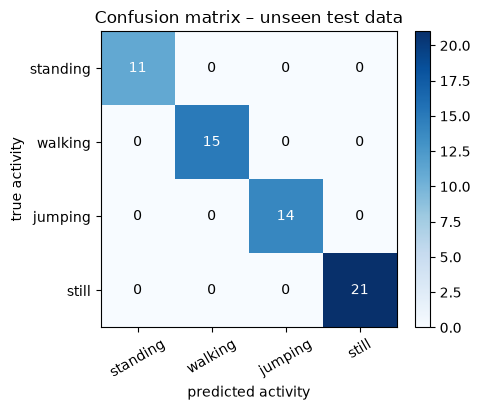

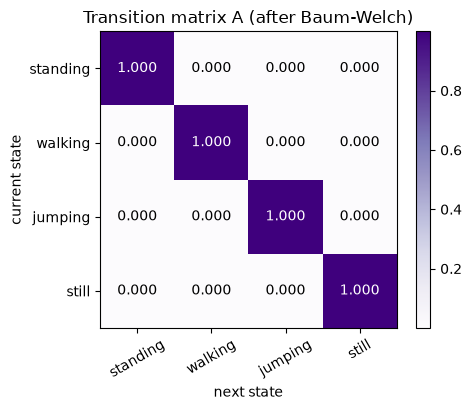

Self-transition probabilities A_kk: {'standing': np.float64(0.999997), 'walking': np.float64(0.999997), 'jumping': np.float64(0.999997), 'still': np.float64(0.999997)}
Learned switching: standing -> still 0.000, still -> standing 0.000; every other off-diagonal entry is at the 1e-06 floor
Initial distribution π: {'standing': np.float64(0.25), 'walking': np.float64(0.25), 'jumping': np.float64(0.25), 'still': np.float64(0.25)}


In [14]:
def heatmap(M, title, fname, fmt, cmap, xlabel, ylabel):
    """Annotated heatmap in the fixed activity order."""
    fig, ax = plt.subplots(figsize=(5, 4.2))
    im = ax.imshow(M, cmap=cmap)
    ax.set_xticks(range(len(STATES)), STATES, rotation=30)
    ax.set_yticks(range(len(STATES)), STATES)
    thresh = M.max() / 2
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, format(M[i, j], fmt), ha="center", va="center",
                    color="white" if M[i, j] > thresh else "black", fontsize=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout()
    fig.savefig(FIG / fname, dpi=150, bbox_inches="tight")
    plt.show()

heatmap(cm, "Confusion matrix – unseen test data", "confusion_matrix.png", "d", "Blues", "predicted activity", "true activity")
# Reorder the learned states into activity order for display
order = np.argsort(mapping)
A_act, pi_act = hmm.A[np.ix_(order, order)], hmm.pi[order]
heatmap(A_act, "Transition matrix A (after Baum-Welch)", "transition_matrix.png", ".3f", "Purples", "next state", "current state")
print("Self-transition probabilities A_kk:", dict(zip(STATES, np.diag(A_act).round(6))))
print(f"Learned switching: standing -> still {A_act[S2I['standing'], S2I['still']]:.3f}, still -> standing {A_act[S2I['still'], S2I['standing']]:.3f}; "
      f"every other off-diagonal entry is at the {hmm.prob_floor:g} floor")
print("Initial distribution π:", dict(zip(STATES, pi_act.round(3))))

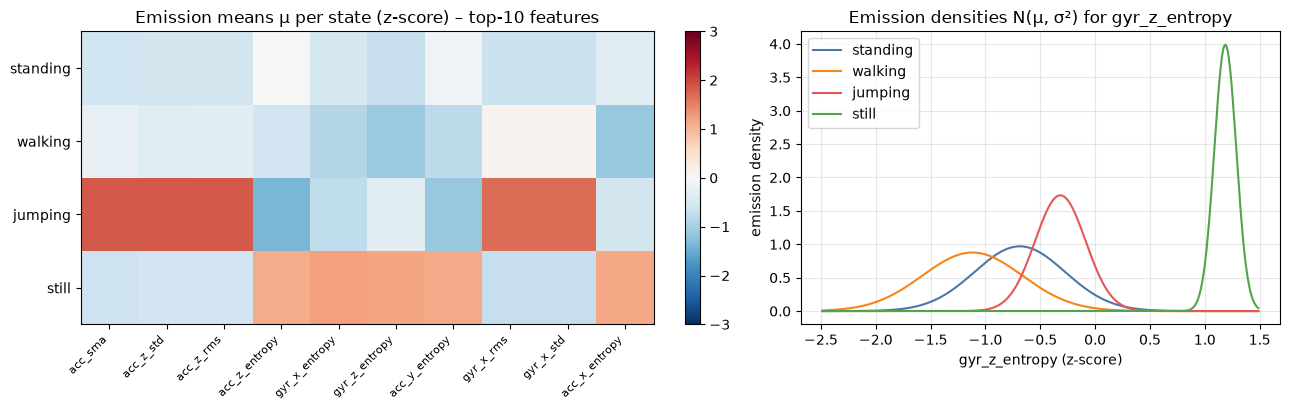

Top-10 features by Fisher ratio (training data): ['acc_sma', 'acc_z_std', 'acc_z_rms', 'acc_z_entropy', 'gyr_x_entropy', 'gyr_z_entropy', 'acc_y_entropy', 'gyr_x_rms', 'gyr_x_std', 'acc_x_entropy']
Best standing-vs-still feature: gyr_z_entropy (separation |Δμ|/√(σ²₁+σ²₂) = 4.42)


In [15]:
# Emission parameters. Left: per-state means only (not the full distributions).
# Right: the full Gaussian densities for one feature.
means_act, vars_act = hmm.means[order], hmm.vars[order]
Ztr_lab = np.concatenate(y_train)
between = np.array([Ztr[Ztr_lab == k].mean(0) for k in range(len(STATES))]).var(0)
within = np.array([Ztr[Ztr_lab == k].var(0) for k in range(len(STATES))]).mean(0)
fisher = between / (within + 1e-9)
top = np.argsort(fisher)[::-1][:10]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
im = axes[0].imshow(means_act[:, top], cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
axes[0].set_yticks(range(len(STATES)), STATES)
axes[0].set_xticks(range(len(top)), [FEATURE_NAMES[i] for i in top], rotation=45, ha="right", fontsize=8)
axes[0].set_title("Emission means μ per state (z-score) – top-10 features")
fig.colorbar(im, ax=axes[0], fraction=0.03)

s_i, t_i = S2I["standing"], S2I["still"]
d_ss = np.abs(means_act[s_i] - means_act[t_i]) / np.sqrt(vars_act[s_i] + vars_act[t_i])
f = int(np.argmax(d_ss))
lo = min(means_act[:, f] - 3 * np.sqrt(vars_act[:, f]))
hi = max(means_act[:, f] + 3 * np.sqrt(vars_act[:, f]))
xs = np.linspace(lo, hi, 400)
for k, s in enumerate(STATES):
    mk, vk = means_act[k, f], vars_act[k, f]
    axes[1].plot(xs, np.exp(-(xs - mk) ** 2 / (2 * vk)) / np.sqrt(2 * np.pi * vk), color=COLORS[s], label=s)
axes[1].set_xlabel(f"{FEATURE_NAMES[f]} (z-score)")
axes[1].set_ylabel("emission density")
axes[1].set_title(f"Emission densities N(μ, σ²) for {FEATURE_NAMES[f]}")
axes[1].legend()
axes[1].grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "emission_parameters.png", dpi=150, bbox_inches="tight")
plt.show()
print("Top-10 features by Fisher ratio (training data):", [FEATURE_NAMES[i] for i in top])
print(f"Best standing-vs-still feature: {FEATURE_NAMES[f]} (separation |Δμ|/√(σ²₁+σ²₂) = {d_ss[f]:.2f})")

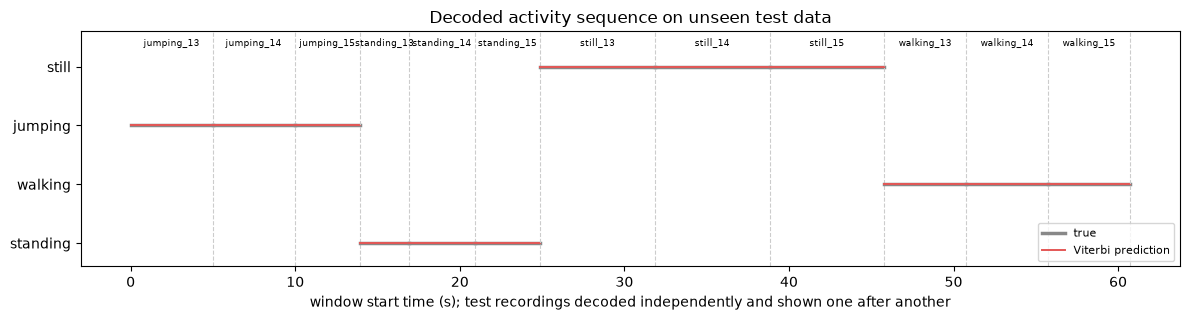

In [16]:
# Each recording was decoded on its own; they are placed side by side only for display
fig, ax = plt.subplots(figsize=(12, 3.3))
t0 = 0.0
for name, act, pred in seg:
    t = t0 + np.arange(len(pred) + 1) * STEP / FS
    ax.step(t, [S2I[act]] * len(pred) + [S2I[act]], where="post", lw=2.5, color="#888888",
            label="true" if t0 == 0 else None)
    ax.step(t, list(pred) + [pred[-1]], where="post", lw=1.4, color="#E45756",
            label="Viterbi prediction" if t0 == 0 else None)
    ax.axvline(t[-1], color="#cccccc", lw=0.8, ls="--")
    ax.text((t[0] + t[-1]) / 2, 3.35, name.replace(".csv", ""), ha="center", fontsize=6.5, rotation=0)
    t0 = t[-1]
ax.set_yticks(range(len(STATES)), STATES)
ax.set_ylim(-0.4, 3.6)
ax.set_xlabel("window start time (s); test recordings decoded independently and shown one after another")
ax.set_title("Decoded activity sequence on unseen test data")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "decoded_sequence.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
# Save every number the report quotes, so the report is filled from executed results
wrong = per_file[per_file.accuracy < 1]
metrics = {
    "n_train_files": len(train_files), "n_test_files": len(test_files),
    "n_train_windows": int(len(train_index)), "n_test_windows": int(len(test_index)),
    "fs_mean": round(FS, 2), "fs_min": round(qc.measured_hz.min(), 2), "fs_max": round(qc.measured_hz.max(), 2),
    "fs_std": round(qc.measured_hz.std(), 3), "dt_min_ms": round(qc.dt_min_ms.min(), 2), "dt_max_ms": round(qc.dt_max_ms.max(), 2),
    "win_samples": WIN, "step_samples": STEP, "bin_hz": round(FS / WIN, 2), "n_features": len(FEATURE_NAMES),
    "n_redundant_pairs": len(redundant),
    "converged": bool(hmm.converged), "converged_iter": hmm.converged_iter,
    "ll_initial": round(history[0], 2), "ll_final": round(history[-1], 2), "ll_decreases": hmm.ll_decreases,
    "train_acc_init": round(train_accuracy(hmm_init, init_mapping), 3), "train_acc_bw": round(train_accuracy(hmm, mapping), 3),
    "test_acc": round(acc, 3), "test_acc_pct": round(100 * acc, 1), "test_correct": int((y_pred == y_true).sum()),
    "test_acc_init": round(acc_init, 3), "test_acc_init_pct": round(100 * acc_init, 1), "test_correct_init": int((y_init == y_true).sum()),
    "cm": cm.tolist(), "A_diag_min": round(np.diag(A_act).min(), 3), "A_diag_max": round(np.diag(A_act).max(), 3),
    "A_offdiag_max": round((A_act - np.diag(np.diag(A_act))).max(), 4),
    "A_diag": dict(zip(STATES, np.diag(A_act).round(6).tolist())),
    "A_standing_still": round(A_act[S2I["standing"], S2I["still"]], 3), "A_still_standing": round(A_act[S2I["still"], S2I["standing"]], 3),
    "train_still_as_standing": int(map_cm[np.where(mapping == S2I["standing"])[0][0], S2I["still"]]),
    "pi": dict(zip(STATES, pi_act.round(3).tolist())),
    "top_features": [FEATURE_NAMES[i] for i in top], "ss_feature": FEATURE_NAMES[f], "ss_separation": round(d_ss[f], 2),
    "misclassified_files": wrong[["file", "original", "true activity", "windows", "accuracy"]].to_dict("records"),
    "tests_passed": sum(p for _, p in results), "tests_total": len(results),
    "per_class": results_df.round(3).to_dict("records"),
}
(ART / "metrics.json").write_text(json.dumps(metrics, indent=2, default=float), encoding="utf-8")
print(json.dumps({k: metrics[k] for k in ["test_acc", "test_acc_init", "converged", "converged_iter", "tests_passed", "tests_total"]}))

{"test_acc": 1.0, "test_acc_init": 1.0, "converged": true, "converged_iter": 2, "tests_passed": 24, "tests_total": 24}


## 10. Still vs standing: what the model uses

The score is perfect, so I checked why. First: how far apart the two static activities are. Then: how the phone was lying, using gravity.

acc_mag_std               gyr_mag_std              
                 min median    max         min median    max
activity                                                    
standing       0.029  0.035  0.149   7.300e-03  0.021  0.066
still          0.005  0.008  0.013   9.000e-04  0.001  0.004

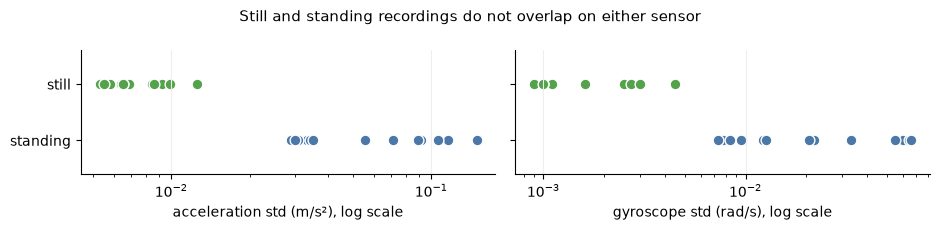

Windows: 61/61, 95 % interval 0.941-1.000
Recordings: 12/12, 95 % interval 0.757-1.000


In [18]:
# How far apart are the two static activities, recording by recording?
statics = manifest[manifest.activity.isin(["still", "standing"])]
display(statics.groupby("activity")[["acc_mag_std", "gyr_mag_std"]].agg(["min", "median", "max"]).round(4))

fig, axes = plt.subplots(1, 2, figsize=(9.5, 2.3), sharey=True)
for ax, col, label in zip(axes, ["acc_mag_std", "gyr_mag_std"], ["acceleration std (m/s²)", "gyroscope std (rad/s)"]):
    for y, act in enumerate(["standing", "still"]):
        g = statics[statics.activity == act]
        ax.scatter(g[col], [y] * len(g), s=60, color=COLORS[act], edgecolor="white", linewidth=1)
    ax.set_xscale("log")
    ax.set_xlabel(label + ", log scale")
    ax.grid(axis="x", color="#eeeeee")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_yticks([0, 1], ["standing", "still"])
axes[0].set_ylim(-0.6, 1.6)
fig.suptitle("Still and standing recordings do not overlap on either sensor", fontsize=11)
fig.tight_layout()
fig.savefig(FIG / "still_vs_standing.png", dpi=150, bbox_inches="tight")
plt.show()

def wilson(k, n, z=1.96):
    """95 % Wilson interval for k successes out of n."""
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

# Windows of one file are not independent, so the recording interval is the honest one
k_win, k_rec = int((y_pred == y_true).sum()), int((per_file.accuracy == 1).sum())
print("Windows: {}/{}, 95 % interval {:.3f}-{:.3f}".format(k_win, len(y_true), *wilson(k_win, len(y_true))))
print("Recordings: {}/{}, 95 % interval {:.3f}-{:.3f}".format(k_rec, len(per_file), *wilson(k_rec, len(per_file))))

Acceleration std is 0.005–0.013 m/s² for still and 0.029–0.149 for standing, so they don't overlap. At the medians the gyroscope gap is bigger: 0.001 against 0.021 rad/s. A phone on a surface reads almost only sensor noise. With 12 of 12 recordings right, the interval still reaches down to about 76 %.

In [19]:
import io
import zipfile

def gravity_tilt(source: str) -> float:
    """Phone tilt from flat in degrees, from the gravity in the uncalibrated accelerometer."""
    p = ROOT / "data" / source
    if p.suffix == ".zip":
        with zipfile.ZipFile(p) as z:
            d = pd.read_csv(io.BytesIO(z.read("AccelerometerUncalibrated.csv")))
    else:
        d = pd.read_csv(p / "AccelerometerUncalibrated.csv")
    d = d.iloc[int(len(d) * 0.2):int(len(d) * 0.9)]     # skip pressing start and stop
    g = d[["x", "y", "z"]].mean().to_numpy()
    return float(np.degrees(np.arccos(min(abs(g[2]) / np.linalg.norm(g), 1))))

sources = pd.concat([manifest[["activity", "original_source"]], excluded[["activity", "original_source"]]])
sources = sources[sources.activity.isin(["still", "standing"])].copy()
sources["tilt_deg"] = sources.original_source.map(gravity_tilt)
display(sources.groupby("activity").tilt_deg.agg(["count", "min", "median", "max"]).round(1))

,count,min,median,max
activity,,,,
standing,15,6.7,10.6,12.8
still,15,1.9,1.9,1.9


Still tilt is 1.9° in every file, against 7–13° for standing. My first still batch was hand-held and read 10–18°, the same pose as standing, which is why it failed.

I also ran this trained model once on those 15 old hand-held files, outside this notebook, since they are no longer in the project. All 58 windows came out as standing, even files quieter than any standing file (0.017 m/s²). So the model separates a phone resting on a surface from a phone in a hand. It knows nothing about the person.

## 11. Discussion

**Result.** 61 of 61 windows and 12 of 12 recordings are correct. Sensitivity and specificity are 1.000 for every activity, and the model before Baum-Welch scores the same.

**What re-recording changed.** My first still batch was hand-held. It scored 84.6 % (44/52), and all 8 errors were still windows called standing, with still sensitivity at 0.333. I replaced those 15 files with the phone flat. The model and features did not change, only the data.

**How much I trust 100 %.** Less than the number suggests. Standing, walking and jumping were tested on a different day from training and held up, even though standing's median std went from 0.034 to 0.106 m/s². Still was not: its test files came minutes after its training files, and all still data is from one session. So I can't fully separate the surface from the day. The size of the gap fits the physics, but I have not tested it.

**Transition matrix.** Every state sits at 0.999997 self-transition and every switch is at the floor. My recordings hold one activity each, so A has never seen a change.

**Baum-Welch.** It converged after 2 iterations and accuracy stayed at 100 %. The labelled start already separates the four states, so EM had nothing to move. With the hand-held data it moved 13 still windows into standing and test accuracy fell from 88.5 % to 84.6 %. EM follows the structure of the data, not my labels.

**Noise.** These movements are below about 5 Hz, so 99.45 Hz is far more than I need.

**Limitations.** One person, one phone, one room, and 11–21 test windows per activity. Clean data for standing, walking and jumping is 80–87 s, under the 90 s target.

**Next.** (1) Record still on other surfaces and days. (2) Add a gravity or tilt feature. (3) Record real transitions so A learns switching. (4) Remove duplicate features. (5) Test other people and phone placements.